## Filtering and trimming messages
### Goal
- Now, we can start using these concepts with models in LangGraph!
- In the next few sessions, we'll build towards a chatbot that has long-term memory.
- Because our chatbot will use messages, let's first talk a bit more about advanced ways to work with messages in graph state.


### Messages as State

In [1]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage 

messages = [AIMessage(f"So you said you were researching ocean mammals?", name="Bot")]
messages.append(HumanMessage(f"Yes, I know about whales. But what others should I learn about?", name="Bilal"))


for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?


In [2]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen2.5:7b")

model.invoke("What is capital of france?")

d:\2026-courses\agent-track\.venv\Lib\site-packages\langsmith\_internal\_addressing.py:104: LangSmithBetaWarning: Addressing runs with `langsmith.address` is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


AIMessage(content='The capital of France is Paris. Paris is not only the capital but also the largest city in France, often renowned for its rich history, culture, art, fashion, and cuisine.', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-11-05T21:30:35.7229981Z', 'done': True, 'done_reason': 'stop', 'total_duration': 8305786700, 'load_duration': 7544162200, 'prompt_eval_count': 35, 'prompt_eval_duration': 128622999, 'eval_count': 38, 'eval_duration': 623468000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a1ad9e-ca55-76b3-9050-12c96334de14-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 35, 'output_tokens': 38, 'total_tokens': 73})

In [3]:
model.invoke(messages).content

"Certainly! Ocean mammals are fascinating subjects for study, and there are many species beyond whales that you might find interesting to learn about. Here are a few key ocean mammals to consider:\n\n1. **Dolphins**: Known for their intelligence and social behavior, dolphins are popular subjects in marine biology. There are several species, including bottlenose dolphins, spinner dolphins, and killer whales (which are actually dolphins).\n\n2. **Pilot Whales**: These are large members of the dolphin family. They are known for their strong social bonds and are often found in large groups.\n\n3. **Porpoises**: Often confused with dolphins, porpoises are smaller and have a distinct look with a rounded snout. Species include the harbor porpoise and the Dall's porpoise.\n\n4. **Sirens**: Also known as manatees, these are slow-moving, herbivorous marine mammals. They are found in warm coastal waters and rivers of the Western Atlantic Ocean.\n\n5. **Sea Otters**: Known for their playful behavi

We run out chat model in a simple graph with MessageState.

In [4]:
from IPython.display import Image, display
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END



In [5]:
# Node
def chat_model_node(state:MessagesState):
    return {
        "messages": model.invoke(state["messages"])
    }




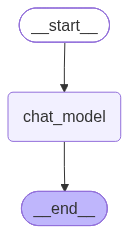

In [6]:
builder = StateGraph(MessagesState)


builder.add_node("chat_model", chat_model_node)

builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)

graph = builder.compile()



# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
output = graph.invoke(
    {
        "messages": messages
    }
)

for m in output["messages"]:
    m.pretty_print()


================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating, and there are several other species besides whales that you might find interesting to learn about. Here are some key ocean mammals that you could explore:

1. **Dolphins and Porpoises**:
   - **Bottlenose Dolphins**: Known for their intelligence and playfulness, often featured in documentaries.
   - **Killer Whales (Orca)**: Sometimes called "blackfish," orcas are apex predators in the ocean and are highly social.
   - **Sperm Whales**: The largest toothed whale, known for their deep diving capabilities and the largest brains.

2. **Seals and Sea Lions**:
   - **Harbor Se

## Reducer

- A practical challenge when working with messages is managing long-running conversations.
- Long-running conversations result in high token usage and latency if we are not careful, because we pass a growing list of messages to the model.
- We have few ways to address this

In [8]:
from langchain_core.messages import RemoveMessage


In [9]:
def filter_messages(state:MessagesState):
    # Delete all but except 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {
        "messages": delete_messages
    }

def chat_model_node(state: MessagesState):    
    return {"messages": [model.invoke(state["messages"])]}

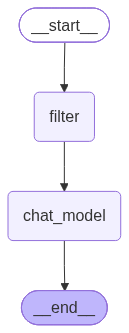

In [10]:
# Build graph
builder = StateGraph(MessagesState)
builder.add_node("filter", filter_messages)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "filter")
builder.add_edge("filter", "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
# Message list with a preamble
messages = [AIMessage("Hi.", name="Bot", id="1")]
messages.append(HumanMessage("Hi.", name="Bilal", id="2"))
messages.append(AIMessage("So you said you were researching ocean mammals?", name="Bot", id="3"))
messages.append(HumanMessage("Yes, I know about whales. But what others should I learn about?", name="Bilal", id="4"))

In [12]:
output = graph.invoke({
    "messages": messages
})

In [13]:
type(output)
print(output.items())   

dict_items([('messages', [AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Bilal', id='4'), AIMessage(content="Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:\n\n1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:\n   - **Blue Whale**: The largest animal on Earth.\n   - **Humpback Whale**: Known for their complex songs and acrobatic displays.\n   - **Sperm Whale**: The largest toothed whale, known for their deep diving abilities.\n\n2. **Dolphins and Porpoises**: These are highly intelligent and social animals.\n   - 

In [14]:
for m in output["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:

1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:
   - **Blue Whale**: The largest animal on Earth.
   - **Humpback Whale**: Known for their complex songs and acrobatic displays.
   - **Sperm Whale**: The largest toothed whale, known for their deep diving abilities.

2. **Dolphins and Porpoises**: These are highly intelligent and social animals.
   - 

## Filtering Messages

- If you don't need or want to modify the graph state, you can just filter the messages you pass to the chat model.

- For example, just pass in a filtered list: llm.invoke(messages[-1:]) to the model.

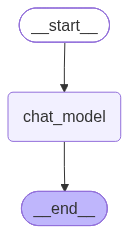

In [15]:
# Node
def chat_model_node(state: MessagesState):
    return {"messages": [model.invoke(state["messages"][-1:])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
messages.append(output['messages'][-1])
messages


[AIMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bot', id='1', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bilal', id='2'),
 AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Bilal', id='4'),
 AIMessage(content="Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:\n\n1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:\n   - **Blue Whale**: The largest animal on Earth.\n   - **Humpback Whale**: Known for their complex songs 

In [17]:
messages[-1:]

[AIMessage(content="Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:\n\n1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:\n   - **Blue Whale**: The largest animal on Earth.\n   - **Humpback Whale**: Known for their complex songs and acrobatic displays.\n   - **Sperm Whale**: The largest toothed whale, known for their deep diving abilities.\n\n2. **Dolphins and Porpoises**: These are highly intelligent and social animals.\n   - **Bottlenose Dolphin**: Common in coastal waters and frequently seen in aquariums.\n   - **Orca (Killer Whale)**: Known for their hunting prowess and complex social structures.\n   - **Dall's Porpoise**: Known for their speed and distinctive markings.\n\n3. **Seals and Sea Lions**: These are pinnipeds, which are true mammals.\n   - **Harbor Seal**: F

In [18]:
messages.append(HumanMessage(f"Tell me more about Narwhals!", name="Bilal"))

In [19]:


for m in messages:
    m.pretty_print()



================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Bilal

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:

1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:
   - **Blue Whale**: The largest animal on Earth.
   - **Humpback Whale**: Known for their complex songs and 

In [20]:
# Invoke, using message filtering
output = graph.invoke({'messages': messages})


In [21]:
for m in output['messages']:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Bilal

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:

1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:
   - **Blue Whale**: The largest animal on Earth.
   - **Humpback Whale**: Known for their complex songs and 

## Trim messages

- Another approach is to [trim messages](https://docs.langchain.com/oss/python/langgraph/add-memory#trim-messages), based upon a set number of tokens.
- This restricts the message history to a specified number of tokens.
- While filtering only returns a post-hoc subset of the messages between agents, trimming restricts the number of tokens that a chat model can use to respond.
- 

In [22]:
from langchain_core.messages import trim_messages



In [28]:
def chat_model_node(state:MessagesState):
    messages = trim_messages(
        state["messages"],
        max_tokens=100,
        strategy= "last",
        token_counter=  ChatOllama(model="llama3.2:latest"),
        allow_partial=False
    )

    return {"messages": [model.invoke(messages)]}


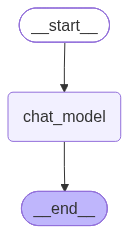

In [29]:
# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
messages.append(output['messages'][-1])
messages.append(HumanMessage(f"Tell me where Orcas live!", name="Bilal"))

messages

[AIMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bot', id='1', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bilal', id='2'),
 AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Bilal', id='4'),
 AIMessage(content="Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:\n\n1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:\n   - **Blue Whale**: The largest animal on Earth.\n   - **Humpback Whale**: Known for their complex songs 

In [26]:
trim_messages(
            messages,
            max_tokens=100,
            strategy="last",
            token_counter=  ChatOllama(model="llama3.2:latest"),
            allow_partial=False
        )

d:\2026-courses\agent-track\.venv\Lib\site-packages\langchain_core\language_models\base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))
d:\2026-courses\agent-track\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
d:\2026-courses\agent-track\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\models--gpt2. Cach

[HumanMessage(content='Tell me where Orcas live!', additional_kwargs={}, response_metadata={}, name='Bilal')]

- messages	The conversation history to trim.
- max_tokens=100: Keep messages within a budget of approximately 100 tokens, as counted by the supplied token counter.
- strategy="last"	Prioritize the most recent messages, removing older ones when necessary.
- token_counter=ChatOllama(...):	Use the Ollama model's token-counting interface to estimate or calculate token usage.
- allow_partial=False: Do not cut an individual message into smaller pieces to fit the budget.

In [30]:
# Invoke, using message trimming in the chat_model_node 
messages_out_trim = graph.invoke({'messages': messages})

In [48]:
messages_out_trim["messages"][4]

AIMessage(content="Certainly! Ocean mammals are fascinating and diverse, and learning about them can provide a rich understanding of marine ecosystems. Here are a few key groups and some notable species you might consider studying:\n\n1. **Whales**: You're already familiar with these, but there are many species to learn about, such as:\n   - **Blue Whale**: The largest animal on Earth.\n   - **Humpback Whale**: Known for their complex songs and acrobatic displays.\n   - **Sperm Whale**: The largest toothed whale, known for their deep diving abilities.\n\n2. **Dolphins and Porpoises**: These are highly intelligent and social animals.\n   - **Bottlenose Dolphin**: Common in coastal waters and frequently seen in aquariums.\n   - **Orca (Killer Whale)**: Known for their hunting prowess and complex social structures.\n   - **Dall's Porpoise**: Known for their speed and distinctive markings.\n\n3. **Seals and Sea Lions**: These are pinnipeds, which are true mammals.\n   - **Harbor Seal**: Fo